# 3.2 Embeddings & Vector Databases (Chroma / FAISS)

**Applied AI Engineering · Module 3: Retrieval-Augmented Generation**

In 3.1 we cut documents into chunks. In this notebook we turn those chunks into **embeddings** (vectors of numbers that capture meaning) and store them in a **vector database** so we can search by meaning.

**By the end you will be able to:**
1. Explain what an embedding is and why similar meanings get similar vectors
2. Calculate cosine similarity, dot product and Euclidean distance
3. Create real embeddings with `sentence-transformers` and *see* them on a 2D map
4. Build a search index with **FAISS** and compare Flat, IVF and HNSW indexes
5. Store, query and filter chunks with **ChromaDB**

## 0. Setup
Run this once (in Colab or a fresh environment). It installs everything the notebook needs. The first run downloads the `all-MiniLM-L6-v2` model (about 90 MB).

In [1]:
# !pip install -q sentence-transformers chromadb faiss-cpu scikit-learn matplotlib numpy

In [2]:
import os, time, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_VERBOSITY"] = "error"
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
np.random.seed(42)
COLORS = {"Finance": "#2a9d8f", "HR": "#e76f51", "Sports": "#264653", "Food": "#e9c46a"}
print("Ready")

Ready


## 1. Where does 3.2 fit in RAG?
The picture below is the full RAG pipeline. The two orange boxes are today's topic.

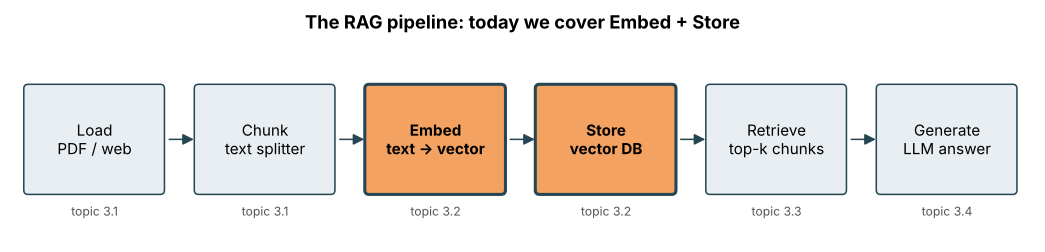

In [3]:
def pipeline_diagram():
    steps = [("Load\nPDF / web", "3.1"), ("Chunk\ntext splitter", "3.1"),
             ("Embed\ntext → vector", "3.2"), ("Store\nvector DB", "3.2"),
             ("Retrieve\ntop-k chunks", "3.3"), ("Generate\nLLM answer", "3.4")]
    fig, ax = plt.subplots(figsize=(12, 2.4))
    ax.set_xlim(0, 12); ax.set_ylim(0, 2.4); ax.axis("off")
    for i, (label, topic) in enumerate(steps):
        x = 0.2 + i * 2
        today = topic == "3.2"
        ax.add_patch(FancyBboxPatch((x, 0.6), 1.55, 1.2, boxstyle="round,pad=0.05",
                     fc="#f4a261" if today else "#e8eef2", ec="#264653", lw=2 if today else 1))
        ax.text(x + 0.78, 1.2, label, ha="center", va="center", fontsize=10,
                fontweight="bold" if today else "normal")
        ax.text(x + 0.78, 0.3, "topic " + topic, ha="center", fontsize=8, color="#555")
        if i < len(steps) - 1:
            ax.add_patch(FancyArrowPatch((x + 1.62, 1.2), (x + 1.98, 1.2), arrowstyle="-|>",
                                         mutation_scale=15, color="#264653"))
    ax.set_title("The RAG pipeline: today we cover Embed + Store", fontsize=12, fontweight="bold")
    plt.show()
pipeline_diagram()

## 2. Intuition: meaning as coordinates
An embedding is like **GPS coordinates for meaning**. Imagine a tiny 2-dimensional "meaning space" where the x-axis is *how much a word is about vehicles* and the y-axis is *how much it is about food*. (Hand-made numbers, just for intuition.)

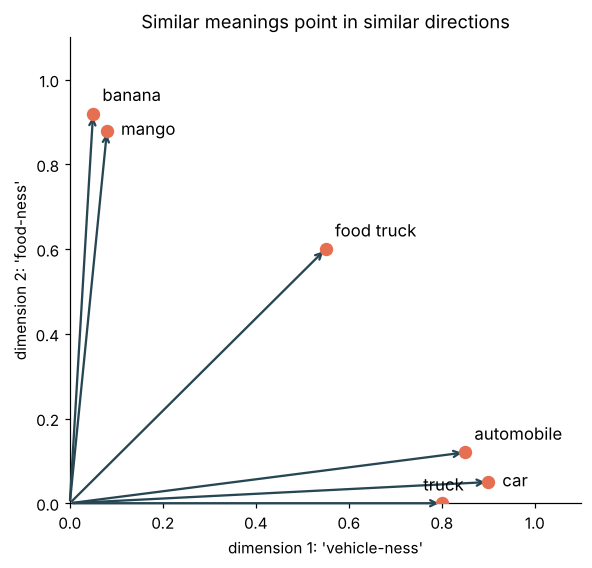

In [4]:
toy = {"car": [0.90, 0.05], "automobile": [0.85, 0.12], "truck": [0.80, 0.0],
       "banana": [0.05, 0.92], "mango": [0.08, 0.88], "food truck": [0.55, 0.60]}

fig, ax = plt.subplots(figsize=(6, 5.5))
for word, (x, y) in toy.items():
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#264653", lw=1.5))
    ax.scatter(x, y, s=60, color="#e76f51", zorder=3)
    off = {"truck": (-0.04, 0.03), "car": (0.03, -0.01), "mango": (0.03, -0.01)}.get(word, (0.02, 0.03))
    ax.text(x + off[0], y + off[1], word, fontsize=11)
ax.set_xlim(0, 1.1); ax.set_ylim(0, 1.1)
ax.set_xlabel("dimension 1: 'vehicle-ness'"); ax.set_ylabel("dimension 2: 'food-ness'")
ax.set_title("Similar meanings point in similar directions")
plt.show()

**What to notice:** *car, automobile, truck* point the same way; *banana, mango* point another way; *food truck* sits in between because it is a bit of both.

Real models do the same thing, but with **384 to 3072 dimensions** learned from billions of sentences. We can't draw 384-D, so later we will squash it down to 2-D with PCA.

## 3. Measuring similarity
Three common ways to compare two vectors **A** and **B**:

| Measure | Formula | Range | Similar when… |
|---|---|---|---|
| Cosine similarity | A·B / (‖A‖‖B‖) | −1 to 1 | **high** (close to 1) |
| Dot product | A·B = Σ aᵢbᵢ | any number | **high** |
| Euclidean (L2) distance | √Σ(aᵢ − bᵢ)² | 0 to ∞ | **low** (close to 0) |

Let's code them from scratch.

In [5]:
def dot(a, b):        return float(np.dot(a, b))
def cosine(a, b):     return dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
def euclidean(a, b):  return float(np.linalg.norm(np.array(a) - np.array(b)))

car, automobile, banana = np.array([0.9, 0.0, 0.7]), np.array([0.88, 0.02, 0.65]), np.array([0.0, 0.95, 0.1])

for name, other in [("automobile", automobile), ("banana", banana)]:
    print(f"car vs {name:10s} | dot = {dot(car, other):.3f} | cosine = {cosine(car, other):.3f} "
          f"| euclidean = {euclidean(car, other):.3f}")

car vs automobile | dot = 1.247 | cosine = 1.000 | euclidean = 0.057
car vs banana     | dot = 0.070 | cosine = 0.064 | euclidean = 1.440


**Why cosine is the default for text:** it only looks at the *angle* between vectors, not their length. A long paragraph and a short sentence about the same thing should still match. The chart below shows this: same direction = cosine 1, perpendicular = 0, opposite = −1.

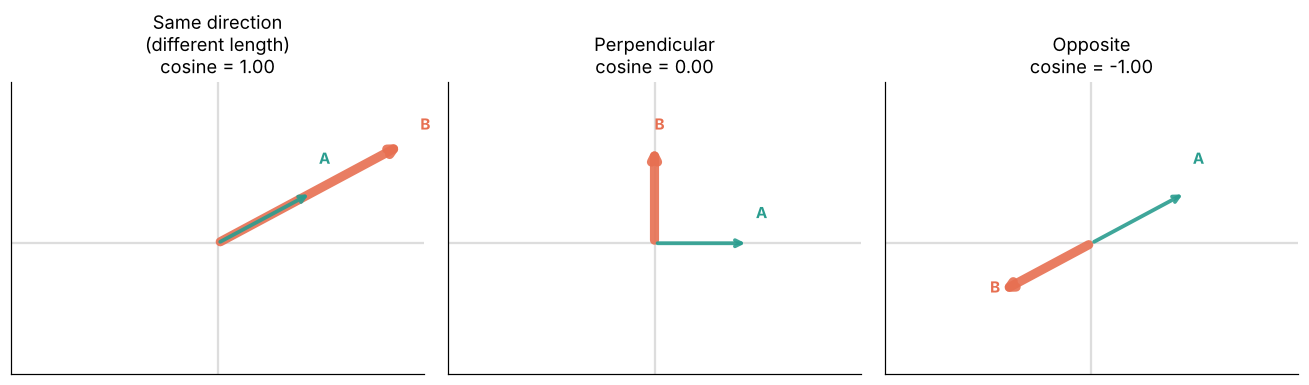

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
cases = [("Same direction\n(different length)", [1, 0.5], [2, 1]),
         ("Perpendicular", [1, 0], [0, 1]),
         ("Opposite", [1, 0.5], [-1, -0.5])]
for ax, (title, a, b) in zip(axes, cases):
    for v, c, lab, lw in [(b, "#e76f51", "B", 6), (a, "#2a9d8f", "A", 2.5)]:
        ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=lw, alpha=0.9))
        ax.text(v[0] * 1.08, v[1] * 1.08 + (0.25 if lab == "A" else 0.05), lab, color=c, fontweight="bold")
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.3, 1.6); ax.axhline(0, color="#ddd"); ax.axvline(0, color="#ddd")
    ax.set_title(f"{title}\ncosine = {cosine(np.array(a), np.array(b)):.2f}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Normalisation trick:** if every vector is scaled to length 1, then *dot product = cosine similarity*, and ranking by L2 distance gives the same order. That is why we often pass `normalize_embeddings=True`.

In [7]:
a, b = np.array([3.0, 4.0]), np.array([4.0, 3.0])
a_n, b_n = a / np.linalg.norm(a), b / np.linalg.norm(b)
print("cosine(a, b)          =", round(cosine(a, b), 4))
print("dot of normalised a,b =", round(dot(a_n, b_n), 4))
print("length of a_n         =", np.linalg.norm(a_n))

cosine(a, b)          = 0.96
dot of normalised a,b = 0.96
length of a_n         = 1.0


## 4. Real embeddings with sentence-transformers
We will use **all-MiniLM-L6-v2**: free, runs on a laptop CPU, outputs **384 numbers** per text.

Our mini "knowledge base" has 16 chunks from four topics: Finance, HR, Sports and Food.

In [8]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("all-MiniLM-L6-v2")

chunks = [
    ("Refunds are processed within 7 working days of the request.", "Finance"),
    ("Invoices must be paid within 30 days of the billing date.", "Finance"),
    ("The company's quarterly revenue grew by 12 percent.", "Finance"),
    ("Expense claims need a receipt and manager approval.", "Finance"),
    ("Employees get 24 paid leave days every year.", "HR"),
    ("New joiners receive their laptop on the first day.", "HR"),
    ("Performance reviews happen twice a year, in June and December.", "HR"),
    ("Work from home is allowed two days per week.", "HR"),
    ("India won the cricket match by five wickets.", "Sports"),
    ("The football team trains every morning at six.", "Sports"),
    ("She finished the marathon in under three hours.", "Sports"),
    ("The tennis final went to a tie-break in the fifth set.", "Sports"),
    ("Biryani is cooked slowly with rice, spices and meat.", "Food"),
    ("Add a pinch of salt to bring out the sweetness of mango lassi.", "Food"),
    ("Paneer tikka is grilled in a tandoor after marinating in yogurt.", "Food"),
    ("Masala chai is brewed with tea leaves, milk, ginger and cardamom.", "Food"),
]
texts  = [t for t, _ in chunks]
labels = [l for _, l in chunks]

embeddings = model.encode(texts, normalize_embeddings=True)
print("Shape:", embeddings.shape, " → 16 chunks × 384 numbers each")
print("First 8 numbers of chunk 0:", np.round(embeddings[0][:8], 3))

Shape: (16, 384)  → 16 chunks × 384 numbers each
First 8 numbers of chunk 0: [-0.079 -0.004  0.074  0.002  0.032 -0.054 -0.04  -0.047]


### 4.1 What does a vector look like?
Each row below is one sentence; each column is one of the 384 dimensions. Individual numbers mean nothing to a human — the *pattern* is what carries meaning.

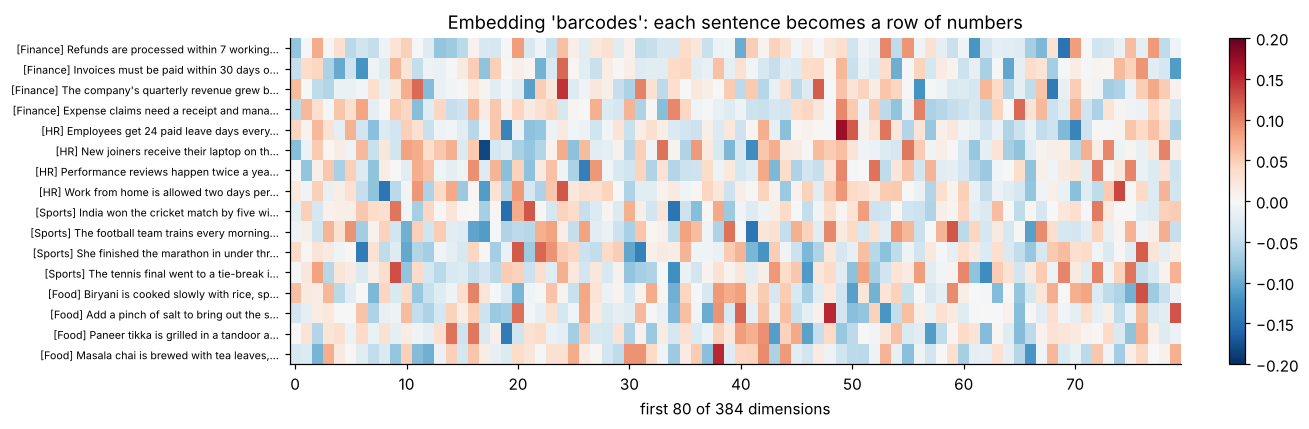

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(embeddings[:, :80], aspect="auto", cmap="RdBu_r", vmin=-0.2, vmax=0.2)
ax.set_yticks(range(len(texts)))
ax.set_yticklabels([f"[{l}] {t[:38]}…" for t, l in chunks], fontsize=7)
ax.set_xlabel("first 80 of 384 dimensions")
ax.set_title("Embedding 'barcodes': each sentence becomes a row of numbers")
plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()

### 4.2 Similarity heatmap
Cosine similarity between every pair of chunks. Since vectors are normalised, this is just `embeddings @ embeddings.T`. Look for the four bright **blocks** along the diagonal — chunks of the same topic are similar to each other.

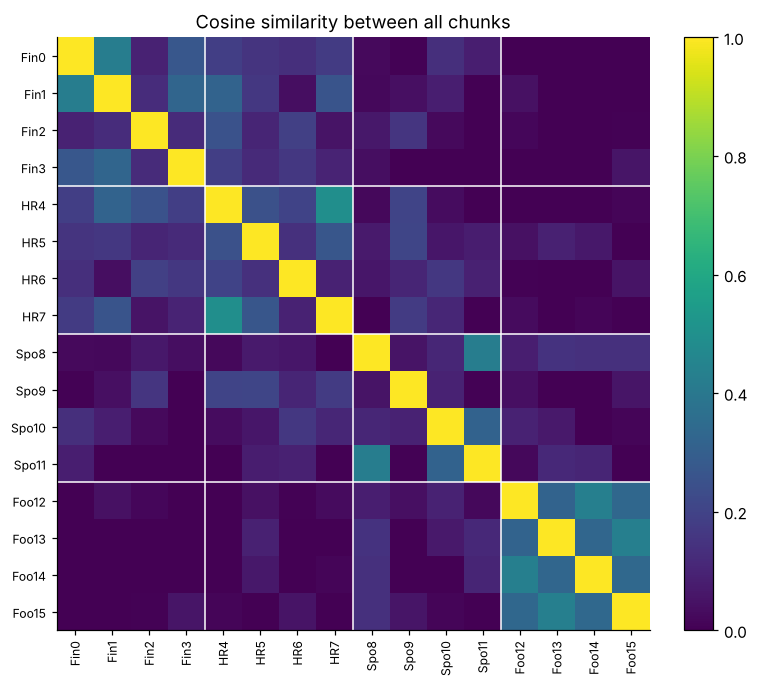

In [10]:
sim = embeddings @ embeddings.T
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(sim, cmap="viridis", vmin=0, vmax=1)
short = [f"{l[:3]}{i}" for i, l in enumerate(labels)]
ax.set_xticks(range(len(short))); ax.set_xticklabels(short, rotation=90, fontsize=8)
ax.set_yticks(range(len(short))); ax.set_yticklabels(short, fontsize=8)
for k in range(1, 4):
    ax.axhline(k * 4 - 0.5, color="white", lw=1); ax.axvline(k * 4 - 0.5, color="white", lw=1)
ax.set_title("Cosine similarity between all chunks")
plt.colorbar(im, fraction=0.046); plt.show()

## 5. Seeing meaning: 384-D squashed to 2-D
We can't draw 384 dimensions, so we use **t-SNE**, a technique that places points on a 2-D map so that points close in 384-D stay close on the map. (Another common option is **PCA**, which is faster but on small text sets usually mixes the clusters more.)

We also place a **question** on the map. Dashed red lines join it to the 3 chunks with the highest cosine similarity in the full 384-D space.

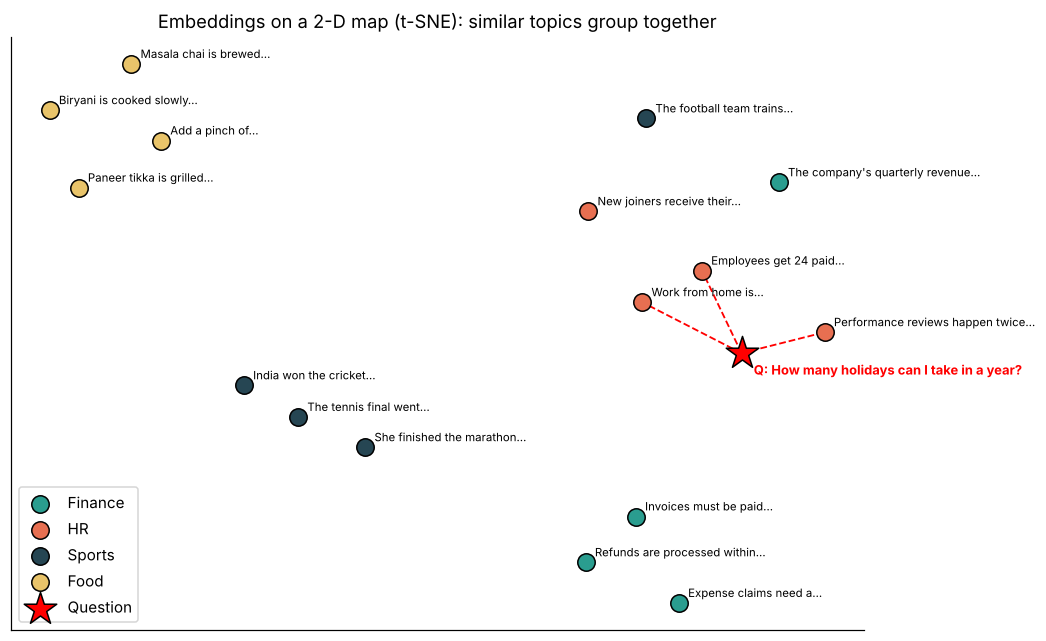

Top 3 chunks for the question:
  0.440  [HR] Employees get 24 paid leave days every year.
  0.329  [HR] Work from home is allowed two days per week.
  0.236  [HR] Performance reviews happen twice a year, in June and December.


In [11]:
from sklearn.manifold import TSNE

question = "How many holidays can I take in a year?"
q_vec = model.encode([question], normalize_embeddings=True)

all_vecs = np.vstack([embeddings, q_vec])
pts_all = TSNE(n_components=2, perplexity=5, metric="cosine", init="pca", random_state=7).fit_transform(all_vecs)
pts, q_pt = pts_all[:-1], pts_all[-1]

fig, ax = plt.subplots(figsize=(10, 7))
top3 = np.argsort(-(embeddings @ q_vec[0]))[:3]
for i in top3:
    ax.plot([q_pt[0], pts[i, 0]], [q_pt[1], pts[i, 1]], "r--", lw=1.2, zorder=1)
for topic, col in COLORS.items():
    idx = [i for i, l in enumerate(labels) if l == topic]
    ax.scatter(pts[idx, 0], pts[idx, 1], s=130, color=col, label=topic, edgecolor="k", zorder=3)
for i, t in enumerate(texts):
    ax.annotate(" ".join(t.split()[:4]) + "…", pts[i], xytext=(6, 4), textcoords="offset points", fontsize=7.5)
ax.scatter(*q_pt, marker="*", s=500, color="red", edgecolor="k", zorder=4, label="Question")
ax.annotate("Q: " + question, q_pt, xytext=(8, -14), textcoords="offset points",
            color="red", fontsize=8.5, fontweight="bold")
ax.set_title("Embeddings on a 2-D map (t-SNE): similar topics group together")
ax.set_xticks([]); ax.set_yticks([]); ax.legend(loc="best")
plt.show()

print("Top 3 chunks for the question:")
for i in top3: print(f"  {float(embeddings[i] @ q_vec[0]):.3f}  [{labels[i]}] {texts[i]}")

The question never uses the word "leave", yet its top match is the leave-days chunk. **That is semantic search.**

## 6. Semantic search vs keyword search
A keyword search only finds chunks that share exact words with the question. Let's compare on three questions phrased differently from the documents.

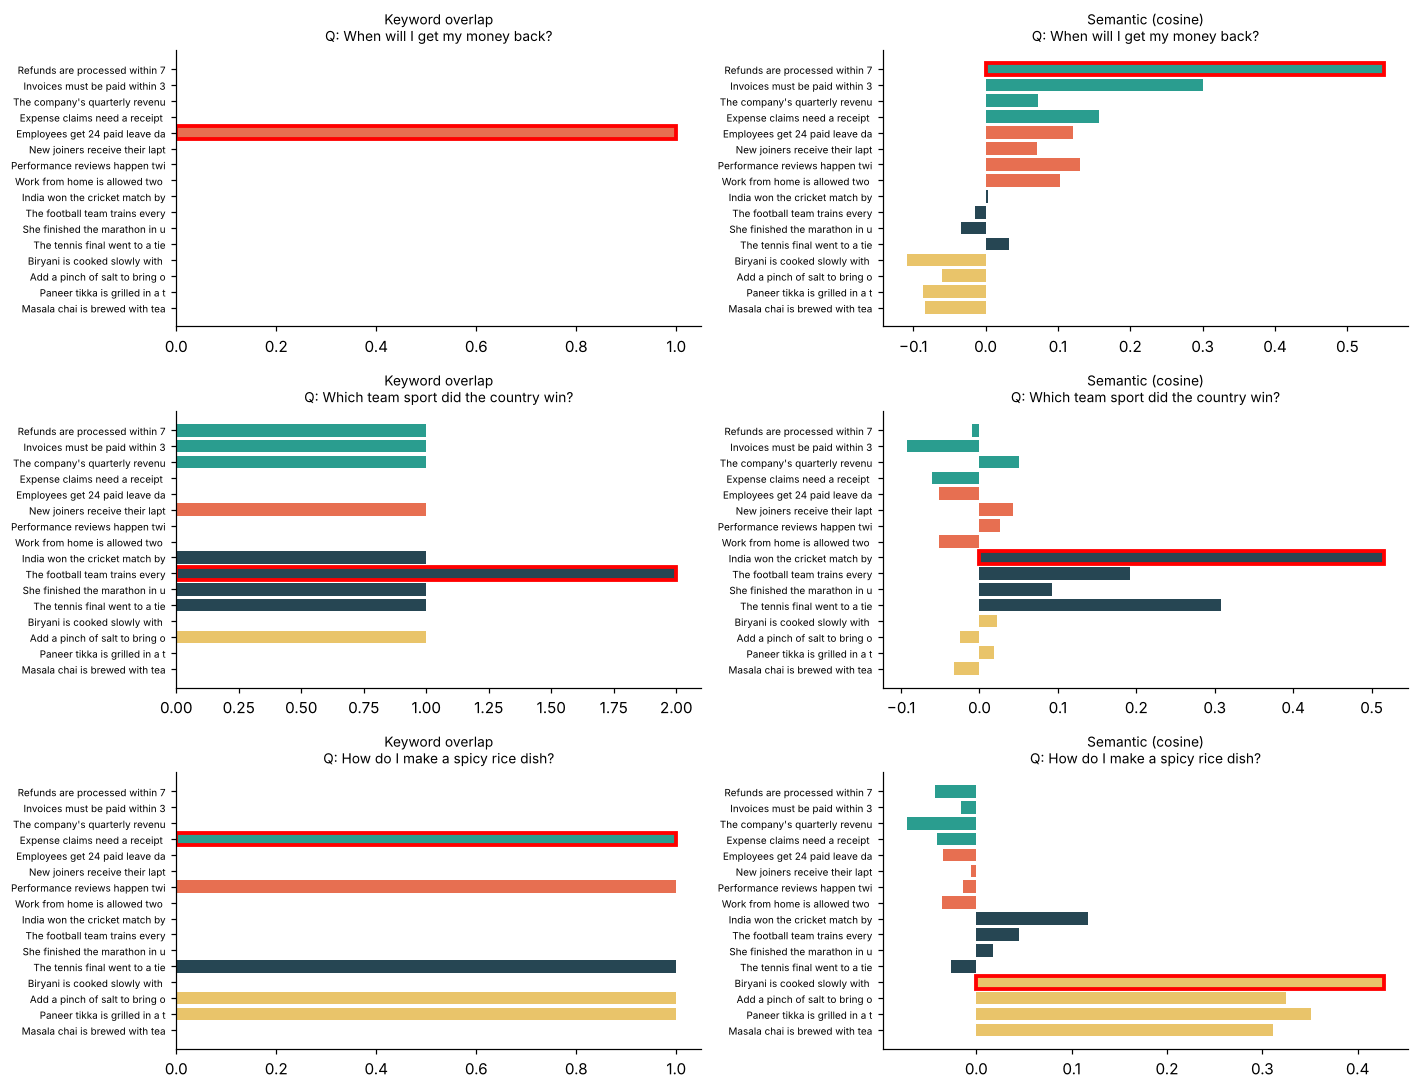

In [12]:
def keyword_scores(q, docs):
    q_words = set(q.lower().replace("?", "").split())
    return np.array([len(q_words & set(d.lower().replace(".", "").split())) for d in docs])

def semantic_scores(q, docs_emb):
    return docs_emb @ model.encode([q], normalize_embeddings=True)[0]

questions = ["When will I get my money back?",
             "Which team sport did the country win?",
             "How do I make a spicy rice dish?"]

fig, axes = plt.subplots(len(questions), 2, figsize=(13, 10))
for r, q in enumerate(questions):
    for c, (name, scores) in enumerate([("Keyword overlap", keyword_scores(q, texts)),
                                        ("Semantic (cosine)", semantic_scores(q, embeddings))]):
        ax = axes[r, c]
        cols = [COLORS[l] for l in labels]
        ax.barh(range(len(texts)), scores, color=cols)
        best = int(np.argmax(scores))
        ax.barh(best, scores[best], color=cols[best], edgecolor="red", lw=2.5)
        ax.set_yticks(range(len(texts))); ax.set_yticklabels([t[:30] for t in texts], fontsize=6.5)
        ax.invert_yaxis()
        ax.set_title(f"{name}\nQ: {q}", fontsize=9)
plt.tight_layout(); plt.show()

**Read the chart:** keyword scores are mostly zero or tied (words like "the" and "I" match by luck), while semantic scores clearly pick the right chunk (red outline).

## 7. FAISS: fast similarity search
**FAISS** (Facebook AI Similarity Search) is a library from Meta. It stores **only vectors** and returns **row numbers**; we keep the text in our own list.

### 7.1 A flat (exact) index

In [13]:
import faiss

dim = embeddings.shape[1]
index = faiss.IndexFlatIP(dim)            # IP = inner product; on normalised vectors this is cosine
index.add(embeddings.astype("float32"))   # FAISS needs float32
print("Vectors in index:", index.ntotal)

def faiss_search(q, k=3):
    qv = model.encode([q], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(qv, k)
    return [(texts[i], labels[i], float(s)) for s, i in zip(scores[0], ids[0])]

for q in ["When will I get my money back?", "Tell me about Indian food with yogurt"]:
    print("\nQ:", q)
    for rank, (t, l, s) in enumerate(faiss_search(q), 1):
        print(f"  {rank}. score={s:.3f} [{l}] {t}")

Vectors in index: 16

Q: When will I get my money back?
  1. score=0.551 [Finance] Refunds are processed within 7 working days of the request.
  2. score=0.301 [Finance] Invoices must be paid within 30 days of the billing date.
  3. score=0.157 [Finance] Expense claims need a receipt and manager approval.

Q: Tell me about Indian food with yogurt
  1. score=0.487 [Food] Paneer tikka is grilled in a tandoor after marinating in yogurt.
  2. score=0.417 [Food] Masala chai is brewed with tea leaves, milk, ginger and cardamom.
  3. score=0.369 [Food] Add a pinch of salt to bring out the sweetness of mango lassi.


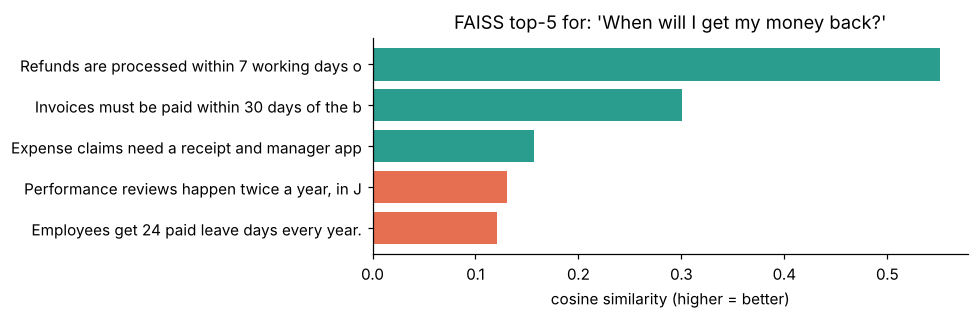

In [14]:
q = "When will I get my money back?"
res = faiss_search(q, k=5)
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh([r[0][:45] for r in res][::-1], [r[2] for r in res][::-1],
        color=[COLORS[r[1]] for r in res][::-1])
ax.set_xlabel("cosine similarity (higher = better)"); ax.set_title(f"FAISS top-5 for: '{q}'")
plt.tight_layout(); plt.show()

### 7.2 L2 vs inner product
`IndexFlatL2` returns **distances** (lower = better). `IndexFlatIP` returns **similarities** (higher = better). On normalised vectors they give the same ranking.

In [15]:
index_l2 = faiss.IndexFlatL2(dim); index_l2.add(embeddings.astype("float32"))
qv = model.encode(["When will I get my money back?"], normalize_embeddings=True).astype("float32")
d, i_l2 = index_l2.search(qv, 3)
s, i_ip = index.search(qv, 3)
print("L2  ids:", i_l2[0], " distances  :", np.round(d[0], 3), "(squared L2)")
print("IP  ids:", i_ip[0], " similarities:", np.round(s[0], 3))
print("Same ranking?", list(i_l2[0]) == list(i_ip[0]))

L2  ids: [0 1 3]  distances  : [0.898 1.398 1.686] (squared L2)
IP  ids: [0 1 3]  similarities: [0.551 0.301 0.157]
Same ranking? True


### 7.3 Index types: Flat vs IVF vs HNSW
With 16 chunks any index is instant. Real systems hold **millions** of chunks, so comparing the query with every vector (Flat) gets slow. Approximate indexes trade a little accuracy for a lot of speed:

- **Flat** — checks every vector. Exact, slow at scale. *(every book in the library)*
- **IVF** — groups vectors into clusters, searches only the closest few clusters. *(go to the right shelf first)*
- **HNSW** — a graph where each vector links to its neighbours; search hops closer and closer. *(ask a librarian who points you to a closer librarian)*

Let's benchmark on **50,000 synthetic vectors**. Real text embeddings form topic clusters, so we generate 500 clusters of points (like 500 topics) instead of pure noise. *Recall@10* = how many of the true top-10 results the index found.

In [16]:
N, D, NQ, K = 50_000, 384, 200, 10
rng = np.random.default_rng(0)
centers = rng.standard_normal((500, D)).astype("float32")
data = (centers[rng.integers(0, 500, N)] + 2.0 * rng.standard_normal((N, D))).astype("float32")
faiss.normalize_L2(data)
queries = (centers[rng.integers(0, 500, NQ)] + 2.0 * rng.standard_normal((NQ, D))).astype("float32")
faiss.normalize_L2(queries)

flat = faiss.IndexFlatIP(D); flat.add(data)
t0 = time.time(); _, truth = flat.search(queries, K); t_flat = (time.time() - t0) / NQ * 1000

quant = faiss.IndexFlatIP(D)
ivf = faiss.IndexIVFFlat(quant, D, 256, faiss.METRIC_INNER_PRODUCT)
ivf.train(data); ivf.add(data); ivf.nprobe = 8

hnsw = faiss.IndexHNSWFlat(D, 32, faiss.METRIC_INNER_PRODUCT)
hnsw.hnsw.efSearch = 64; hnsw.add(data)

def bench(idx):
    t0 = time.time(); _, found = idx.search(queries, K); ms = (time.time() - t0) / NQ * 1000
    recall = np.mean([len(set(f) & set(t)) / K for f, t in zip(found, truth)])
    return ms, recall

results = {"Flat": (t_flat, 1.0), "IVF (nprobe=8)": bench(ivf), "HNSW (M=32)": bench(hnsw)}
for name, (ms, rc) in results.items():
    print(f"{name:15s}  {ms:7.3f} ms/query   recall@10 = {rc:.2f}")

Flat               3.050 ms/query   recall@10 = 1.00
IVF (nprobe=8)     0.155 ms/query   recall@10 = 0.84
HNSW (M=32)        0.168 ms/query   recall@10 = 0.99


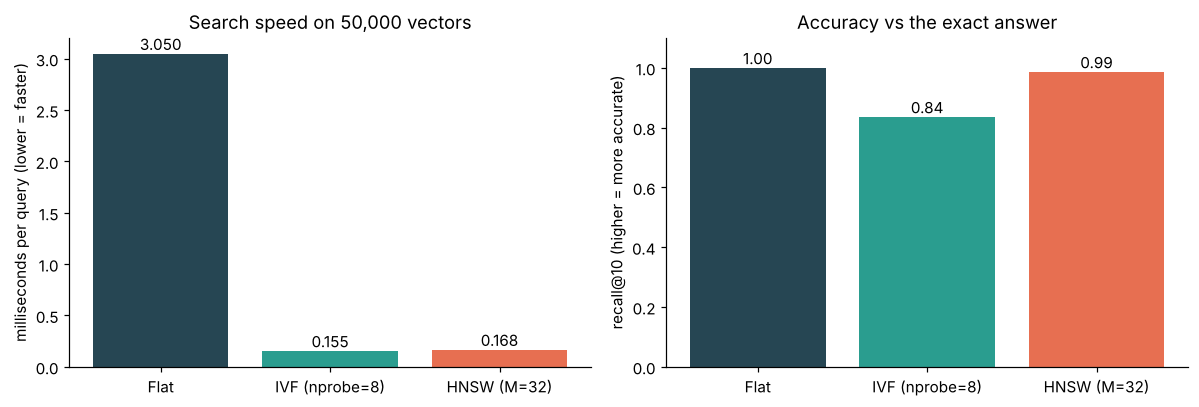

In [17]:
names = list(results); ms = [results[n][0] for n in names]; rc = [results[n][1] for n in names]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bars = a1.bar(names, ms, color=["#264653", "#2a9d8f", "#e76f51"])
a1.bar_label(bars, fmt="%.3f"); a1.set_ylabel("milliseconds per query (lower = faster)")
a1.set_title("Search speed on 50,000 vectors")
bars = a2.bar(names, rc, color=["#264653", "#2a9d8f", "#e76f51"])
a2.bar_label(bars, fmt="%.2f"); a2.set_ylim(0, 1.1); a2.set_ylabel("recall@10 (higher = more accurate)")
a2.set_title("Accuracy vs the exact answer")
plt.tight_layout(); plt.show()

**Takeaway:** Flat is always exact. IVF and HNSW are faster but may miss a few true neighbours. Try changing `ivf.nprobe` or `hnsw.hnsw.efSearch` and re-run: higher = more accurate but slower.

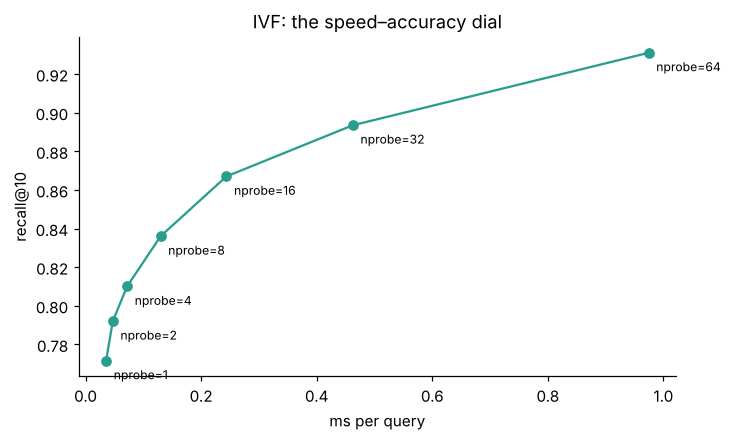

In [18]:
# Speed vs accuracy trade-off for IVF: search more clusters → better recall, slower
probes, curve = [1, 2, 4, 8, 16, 32, 64], []
for p in probes:
    ivf.nprobe = p; curve.append(bench(ivf))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([c[0] for c in curve], [c[1] for c in curve], "o-", color="#2a9d8f")
for p, (m, r) in zip(probes, curve):
    ax.annotate(f"nprobe={p}", (m, r), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax.set_xlabel("ms per query"); ax.set_ylabel("recall@10"); ax.set_title("IVF: the speed–accuracy dial")
plt.show()

### 7.4 Saving and loading a FAISS index
FAISS saves only vectors, so save your texts separately (e.g. JSON).

In [19]:
import json
faiss.write_index(index, "kb.index")
json.dump(chunks, open("kb_chunks.json", "w"))

index2 = faiss.read_index("kb.index"); chunks2 = json.load(open("kb_chunks.json"))
print("Reloaded:", index2.ntotal, "vectors and", len(chunks2), "texts")

Reloaded: 16 vectors and 16 texts


## 8. ChromaDB: a full vector database
Chroma does more for you than FAISS:
- **embeds** text automatically (you give it an embedding function)
- stores **ids, vectors, documents and metadata** together
- supports **metadata filters** (`where=`)
- can **persist** to disk

Each record looks like this:

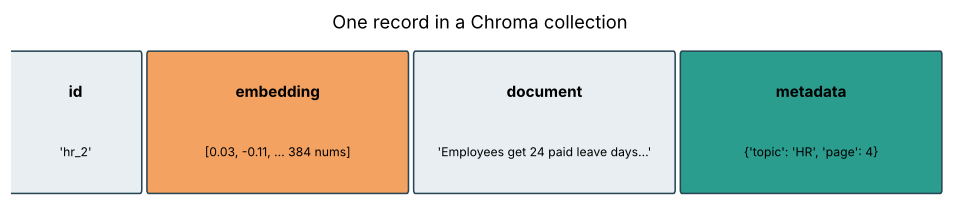

In [20]:
fig, ax = plt.subplots(figsize=(11, 2)); ax.axis("off")
parts = [("id", "'hr_2'", "#e8eef2"), ("embedding", "[0.03, -0.11, … 384 nums]", "#f4a261"),
         ("document", "'Employees get 24 paid leave days…'", "#e8eef2"), ("metadata", "{'topic': 'HR', 'page': 4}", "#2a9d8f")]
x = 0
for name, val, col in parts:
    w = 1.6 if name == "id" else 3.1
    ax.add_patch(FancyBboxPatch((x, 0.1), w - 0.1, 0.8, boxstyle="round,pad=0.02", fc=col, ec="#264653"))
    ax.text(x + w / 2 - 0.05, 0.65, name, ha="center", fontweight="bold")
    ax.text(x + w / 2 - 0.05, 0.3, val, ha="center", fontsize=8)
    x += w
ax.set_xlim(0, x); ax.set_ylim(0, 1); ax.set_title("One record in a Chroma collection"); plt.show()

In [21]:
import chromadb
from chromadb.utils import embedding_functions

client = chromadb.Client()   # in-memory; use chromadb.PersistentClient(path="./chroma_db") to save to disk
ef = embedding_functions.SentenceTransformerEmbeddingFunction(model_name="all-MiniLM-L6-v2")

try: client.delete_collection("company_kb")   # so this cell can be re-run
except Exception: pass

collection = client.create_collection(
    name="company_kb",
    embedding_function=ef,
    metadata={"hnsw:space": "cosine"})        # use cosine distance (default is L2)

collection.add(
    ids=[f"{l.lower()}_{i}" for i, (_, l) in enumerate(chunks)],
    documents=texts,
    metadatas=[{"topic": l, "page": i // 4 + 1} for i, (_, l) in enumerate(chunks)])

print("Records in collection:", collection.count())
print(collection.peek(limit=2)["documents"])

Records in collection: 16
['Refunds are processed within 7 working days of the request.', 'Invoices must be paid within 30 days of the billing date.']


In [22]:
res = collection.query(query_texts=["How many holidays can I take in a year?"], n_results=3)
for doc, meta, dist in zip(res["documents"][0], res["metadatas"][0], res["distances"][0]):
    print(f"distance={dist:.3f}  similarity={1 - dist:.3f}  [{meta['topic']}] {doc}")

distance=0.560  similarity=0.440  [HR] Employees get 24 paid leave days every year.
distance=0.671  similarity=0.329  [HR] Work from home is allowed two days per week.
distance=0.764  similarity=0.236  [HR] Performance reviews happen twice a year, in June and December.


With `hnsw:space = cosine`, Chroma reports **distance = 1 − cosine similarity**, so **smaller distance = better match**.

### 8.1 Metadata filtering
Search only inside one topic (or one file, one page range…). This is very useful for "search only this PDF" features.

In [23]:
q = "What is the schedule?"
plain    = collection.query(query_texts=[q], n_results=3)
filtered = collection.query(query_texts=[q], n_results=3, where={"topic": "Sports"})
print("Without filter:"); [print("  ", m["topic"], "|", d) for d, m in zip(plain["documents"][0], plain["metadatas"][0])]
print("With where={'topic': 'Sports'}:"); [print("  ", m["topic"], "|", d) for d, m in zip(filtered["documents"][0], filtered["metadatas"][0])]

# Numeric filters work too
pg = collection.query(query_texts=[q], n_results=3, where={"page": {"$gte": 3}})
print("With page >= 3:", [m["page"] for m in pg["metadatas"][0]])

Without filter:
   Sports | The football team trains every morning at six.
   HR | Work from home is allowed two days per week.
   HR | Employees get 24 paid leave days every year.
With where={'topic': 'Sports'}:
   Sports | The football team trains every morning at six.
   Sports | She finished the marathon in under three hours.
   Sports | The tennis final went to a tie-break in the fifth set.
With page >= 3: [3, 3, 3]


### 8.2 Update and delete
Vector DBs are not write-once: you can fix or remove chunks.

In [24]:
collection.update(ids=["hr_4"], documents=["Employees get 30 paid leave days every year."])
collection.delete(ids=["sports_11"])
print("Count after delete:", collection.count())
print(collection.query(query_texts=["annual leave"], n_results=1)["documents"])

Count after delete: 15
[['Employees get 30 paid leave days every year.']]


## 9. Putting it together: chunks → embeddings → Chroma → answer context
A small end-to-end example using a policy text. We chunk it simply here (in 3.1 you used `RecursiveCharacterTextSplitter`; the result is the same idea: a list of strings).

In [25]:
policy = '''Leave Policy. Full-time employees receive 24 days of paid leave per year. Unused leave up to 10 days can be carried forward.
Sick Leave. Employees get 8 days of sick leave. A medical certificate is required for more than 2 consecutive days.
Travel Policy. Economy class is used for flights under 6 hours. Hotel bookings must be made through the travel desk.
Reimbursement. Claims must be submitted within 30 days with original receipts. Approved claims are paid with the next salary.
IT Policy. Laptops must be locked when unattended. Passwords are changed every 90 days.'''

policy_chunks = [line.strip() for line in policy.split("\n") if line.strip()]
for c in policy_chunks: print("•", c[:80], "…")

try: client.delete_collection("policy_kb")
except Exception: pass
policy_db = client.create_collection("policy_kb", embedding_function=ef, metadata={"hnsw:space": "cosine"})
policy_db.add(ids=[f"p{i}" for i in range(len(policy_chunks))], documents=policy_chunks,
              metadatas=[{"section": c.split(".")[0]} for c in policy_chunks])

def retrieve(question, k=2):
    r = policy_db.query(query_texts=[question], n_results=k)
    return r["documents"][0], [1 - d for d in r["distances"][0]]

question = "Can I fly business class to Mumbai?"
docs, sims = retrieve(question)
prompt = "Answer using only this context:\n\n" + "\n".join(f"- {d}" for d in docs) + f"\n\nQuestion: {question}"
print("\n--- Prompt we would send to the LLM (topic 3.3/3.4) ---\n" + prompt)

• Leave Policy. Full-time employees receive 24 days of paid leave per year. Unused …
• Sick Leave. Employees get 8 days of sick leave. A medical certificate is require …
• Travel Policy. Economy class is used for flights under 6 hours. Hotel bookings m …
• Reimbursement. Claims must be submitted within 30 days with original receipts. A …
• IT Policy. Laptops must be locked when unattended. Passwords are changed every 9 …

--- Prompt we would send to the LLM (topic 3.3/3.4) ---
Answer using only this context:

- Travel Policy. Economy class is used for flights under 6 hours. Hotel bookings must be made through the travel desk.
- Sick Leave. Employees get 8 days of sick leave. A medical certificate is required for more than 2 consecutive days.

Question: Can I fly business class to Mumbai?


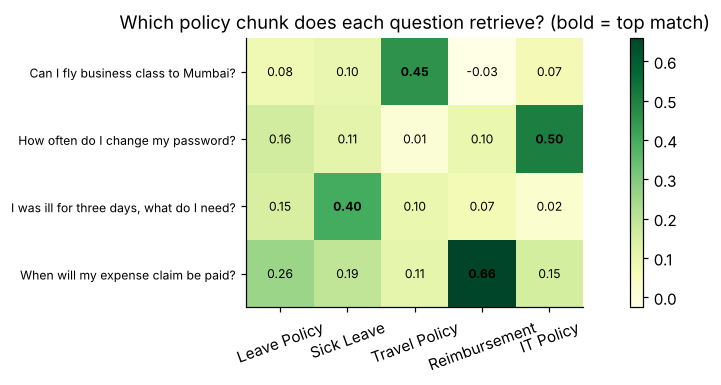

In [26]:
qs = ["Can I fly business class to Mumbai?", "How often do I change my password?",
      "I was ill for three days, what do I need?", "When will my expense claim be paid?"]
sections = [c.split(".")[0] for c in policy_chunks]
all_emb = model.encode(policy_chunks, normalize_embeddings=True)
mat = model.encode(qs, normalize_embeddings=True) @ all_emb.T

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(mat, cmap="YlGn")
ax.set_xticks(range(len(sections))); ax.set_xticklabels(sections, rotation=20)
ax.set_yticks(range(len(qs))); ax.set_yticklabels(qs, fontsize=8)
for r in range(len(qs)):
    for c in range(len(sections)):
        ax.text(c, r, f"{mat[r, c]:.2f}", ha="center", va="center", fontsize=8,
                fontweight="bold" if c == mat[r].argmax() else "normal")
ax.set_title("Which policy chunk does each question retrieve? (bold = top match)")
plt.colorbar(im, fraction=0.03); plt.tight_layout(); plt.show()

## 10. Chroma vs FAISS: when to use which

| | ChromaDB | FAISS |
|---|---|---|
| Type | Vector **database** | Similarity-search **library** |
| Embeds text for you | ✅ | ❌ (you pass vectors) |
| Stores text + metadata | ✅ | ❌ (only vectors) |
| Metadata filters | ✅ `where=` | ❌ |
| Persist to disk | `PersistentClient` | `write_index` / `read_index` |
| Index types | HNSW | Flat, IVF, HNSW, PQ, … |
| GPU | ❌ | ✅ |
| Best for | Prototypes, small–medium RAG apps | Millions of vectors, max speed |

**With LangChain** (both take the chunks from 3.1):
```python
from langchain_community.vectorstores import Chroma, FAISS
from langchain_huggingface import HuggingFaceEmbeddings
emb = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
db = Chroma.from_documents(chunks, emb)      # or FAISS.from_documents(chunks, emb)
db.similarity_search("How many leave days?", k=3)
```

## 11. Common mistakes
1. Using **different models** for documents and questions → vectors live in different "maps".
2. Forgetting **normalisation** with dot product / `IndexFlatIP`.
3. Reading a **distance** as a similarity (Chroma & L2: lower is better).
4. Passing `float64` to FAISS → convert with `.astype("float32")`.
5. Changing the embedding model without **re-embedding** everything already stored.
6. Chunks longer than the model's max input (≈256 tokens for MiniLM) get **cut off** silently.

## 12. Exercises
1. Add 4 chunks about **Technology** to section 4 and re-draw the PCA map. Does a new cluster appear?
2. Swap the model for `all-mpnet-base-v2` (768-D). Compare the similarity heatmap. Is it sharper?
3. In section 7.3, plot recall vs `hnsw.hnsw.efSearch` for 16, 32, 64, 128, 256.
4. Load a PDF with your 3.1 code, chunk it, store it in a `PersistentClient`, restart the kernel and query it again.
5. Write a question that retrieves the **wrong** chunk. Why did it fail? (Hint: ambiguity, short chunks, or missing information.)